<a href="https://colab.research.google.com/github/judithwang021/judith-6070/blob/main/WeeklyModules/Week12/judithwang021_participation_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from pathlib import Path
!pip -q install dataframe_image
import dataframe_image as dfi

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('github_token')
owner = 'judithwang021' # Replace with the GitHub repository owner
repository = 'judith-6070' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/judith-6070


In [3]:
file_path = Path("/content/judith-6070/data/Student Performance Data.csv")
df = pd.read_csv(file_path)

In [14]:
male_completed = df[
    (df['gender'] == 'male') &
    (df['test preparation course'] == 'completed')
]['total score']

In [15]:
others = df[
    ~((df['gender'] == 'male') &
     (df['test preparation course'] == 'completed'))
]['total score']

In [16]:
male_completed.mean()

np.float64(212.3448275862069)

In [17]:
others.mean()

np.float64(201.409200968523)

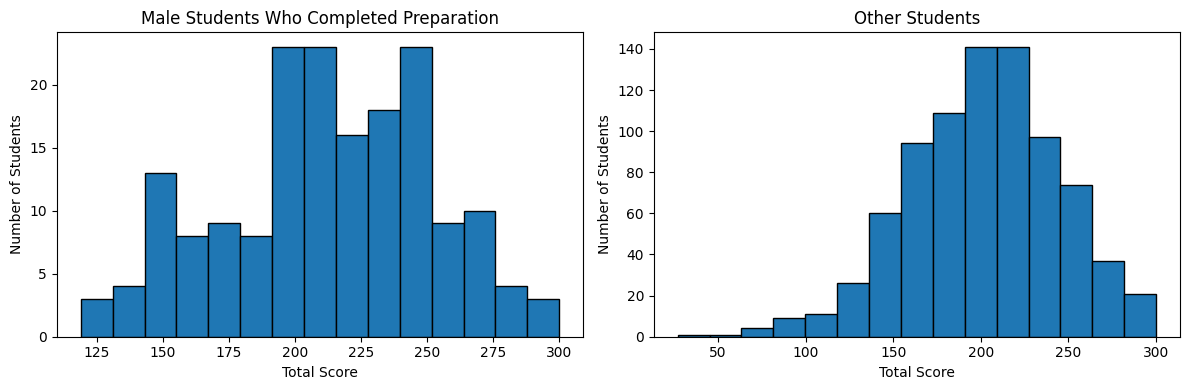

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(male_completed, bins=15, edgecolor='black')
ax[0].set_title('Male Students Who Completed Preparation')
ax[0].set_xlabel('Total Score')
ax[0].set_ylabel('Number of Students')

ax[1].hist(others, bins=15, edgecolor='black')
ax[1].set_title('Other Students')
ax[1].set_xlabel('Total Score')
ax[1].set_ylabel('Number of Students')

plt.tight_layout()
plt.show()

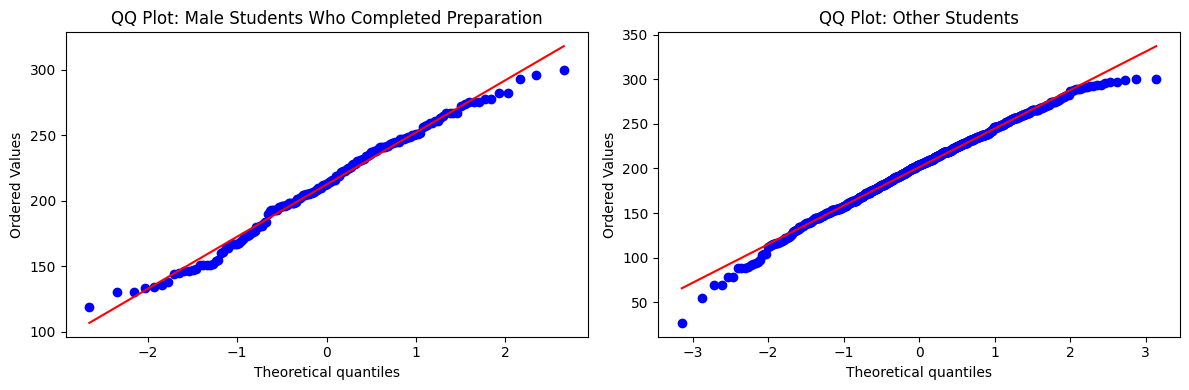

In [19]:
ig, ax = plt.subplots(1, 2, figsize=(12, 4))

stats.probplot(male_completed, dist='norm', plot=ax[0])
ax[0].set_title('QQ Plot: Male Students Who Completed Preparation')

stats.probplot(others, dist='norm', plot=ax[1])
ax[1].set_title('QQ Plot: Other Students')

plt.tight_layout()
plt.show()

In [21]:
male_normality = stats.normaltest(male_completed)
male_normality

NormaltestResult(statistic=np.float64(5.186330099648431), pvalue=np.float64(0.07478297328266548))

In [22]:
others_normality = stats.normaltest(others)
others_normality

NormaltestResult(statistic=np.float64(13.703333826910951), pvalue=np.float64(0.00105769114304216))

In [24]:
t_statistic, p_value = stats.ttest_ind(
    male_completed,
    others,
    equal_var=False)

print('t-statistic:', t_statistic)
print('p-value:', p_value)

t-statistic: 3.257451981231156
p-value: 0.0012695902226222658


Because the p value is approximately 0.0013, which is far below 0.05, the null hypothesis that the two groups have equal mean total scores is rejected. So, difference between male students who completed the test preparation course and the others is significant, with male students who completed the test preparation course having an average total score of 212.34 and the others having an average total score of 201.41.

In [25]:
standard_lunch = df[df['lunch'] == 'standard']['total score']
reduced_lunch = df[df['lunch'] == 'free/reduced']['total score']

In [26]:
standard_lunch.mean()

np.float64(212.51162790697674)

In [27]:
reduced_lunch.mean()

np.float64(186.59718309859156)

In [28]:
t_lunch, p_lunch = stats.ttest_ind(
    standard_lunch,
    reduced_lunch,
    equal_var=False)

print('Mean difference:', standard_lunch.mean() - reduced_lunch.mean())
print('t-statistic:', t_lunch)
print('p-value:', p_lunch)

Mean difference: 25.914444808385184
t-statistic: 9.323207349610827
p-value: 1.582969042730361e-19


Students who received a standard lunch had an average total score of 212.51, while students who received free or reduced lunch had an average total score of 186.60. The p-value is 1.582969042730361e-19, which is far below 0.001, indicating that the difference between two lunch types is statistically significant.